# C-KLT Phase-Transition Sweep

**Goal.** Characterise how the single-receiver **C-KLT** detection pipeline behaves as a function of the injected signal SNR, and compare the empirical detectability against the **Baik–Ben Arous–Péché (BBP) phase transition** predicted by Random Matrix Theory.

For each run we:
1. **Generate** a GUPPI raw voltage file with `setigen` (one synthetic receiver), injecting a drifting CW tone at a controlled SNR, random baseband frequency offset, and random drift rate.
2. **Reconstruct** the signal with the C-KLT (`seti_klt.KLT.apply_cklt`).
3. **Count signal eigenvalues** with the Kritchman & Nadler (2009) rank estimator.
4. **Record** — and persist incrementally — the initial SNR, the reconstructed SNR, the number of K&N eigenvalues, whether a signal was found, whether the dominant eigenvalue crossed the phase transition, and a set of supporting diagnostics.

### Dimensionality (MeerKAT-like)
The C-KLT windows a 1-D voltage stream into `K` blocks of `W` samples and diagonalises the `W×W` covariance. The RMT roles map onto the MeerKAT beamformed-stamp dimensions used elsewhere in the project:

| C-KLT | MR-KLT / MeerKAT stamp | role |
|-------|------------------------|------|
| `W` (window size) | `N_A` antennas | covariance dimension |
| `K` (# windows) | timesteps | # realisations |
| `γ = W/(K-1)` | `γ = N_A/(K-1)` | aspect ratio |

The defaults `W = 63`, `K = 293` give `γ = 63/292 ≈ 0.216`, matching the real MeerKAT stamps. The **phase-transition threshold** is `√γ ≈ 0.46` (in units of σ²): a population spike `ℓ = λ_s/σ²` only escapes the Marchenko–Pastur bulk — and becomes detectable — when `ℓ > √γ`.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from helpers import (
    CKLTConfig,
    generate_cklt_raw,
    analyze_cklt,
    append_result_row,
    load_results,
    run_sweep,
    RESULT_FIELDS,
    _HAS_CUPY,
)
from seti_klt import KLT, TracyWidomTW2
from seti_klt.utils.io import SimpleLogger, LogLevel

print(f"CuPy / GPU available: {_HAS_CUPY}")

/mnt/c/Users/gigig/Documents/University/SETI/codes/.venv/lib/python3.12/site-packages/blimpy/__init__.py:21: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


CuPy / GPU available: True


## 1. Configuration

All fixed instrument and processing parameters live in `CKLTConfig`.

**Backend.** The code is fully CuPy-capable: with `use_gpu=True` the raw voltages are synthesised on the GPU via the `setigen` CuPy backend and the spectral-SNR FFTs run on the GPU too. In this environment the **first** GPU generation in a fresh kernel pays a long one-off CuPy kernel-compilation cost (tens of seconds), after which each run is ~2 s. The CPU path is a reliable ~3 s/run with no warmup, so the default below is `use_gpu=False`; set it to `_HAS_CUPY` to opt into the GPU (the warmup is amortised over a long sweep).

In [4]:
cfg = CKLTConfig(
    window_size=63,      # W  ~ N_A antennas
    k_windows=293,       # K  ~ timesteps   => gamma = 63/292 ~ 0.216
    target_channel=30,
    use_gpu=True,       # CPU generation (reliable, no warmup); set to _HAS_CUPY for GPU
    out_root="outputs",
)

print(f"W = {cfg.window_size} | K = {cfg.k_windows} | num_samples = {cfg.num_samples}")
print(f"gamma = {cfg.gamma:.4f} | BBP threshold sqrt(gamma) = {cfg.bbp_threshold:.4f}")
print(f"chan_bw = {cfg.chan_bw/1e6:.4f} MHz | target channel centre = {cfg.channel_center_hz()/1e6:.3f} MHz")

W = 63 | K = 293 | num_samples = 18459
gamma = 0.2158 | BBP threshold sqrt(gamma) = 0.4645
chan_bw = 2.9297 MHz | target channel centre = 1587.891 MHz


## 2. Single-run demonstration

Before the full sweep, generate one strong injection and inspect the eigenspectrum and reconstruction, to confirm the pipeline behaves as expected and the tone is recovered at the injected frequency.

In [ ]:
demo_logger = SimpleLogger(level=LogLevel.WARNING, file_output=False)
tw2 = TracyWidomTW2()  # build the Tracy-Widom LUT once and reuse everywhere

gen = generate_cklt_raw(
    snr_db=-20.0,
    freq_offset_frac=0.317,
    drift_rate_hz_s=2.0,
    config=cfg,
    file_stem="outputs/raw_data/demo",
    seed=0,
)
res = analyze_cklt(gen, config=cfg, logger=demo_logger)

for k in ("snr_db", "lambda1", "lambda_max_MP", "l_pop_hat", "bbp_threshold_sqrt_gamma",
          "supercritical", "n_signals_KN", "signal_found", "signal_confirmed",
          "recon_gain_db", "freq_err_hz"):
    print(f"{k:>26}: {res[k]}")


=== LOADING GUPPI DATA


Reading blocks: 32.8ksamp [00:00, 220ksamp/s]                 



=== APPLYING C-KLT

=== APPLYING C-KLT
                    snr_db: -20.0
                   lambda1: 119106.3453940052
             lambda_max_MP: 4764.604284631158
                 l_pop_hat: 52.33732782973732
  bbp_threshold_sqrt_gamma: 0.4636993259067953
             supercritical: 1
              n_signals_KN: 1
              signal_found: 1
          signal_confirmed: 1
             recon_gain_db: 27.943346377029144
               freq_err_hz: 78.88047497150475



=== LOADING GUPPI DATA


Reading blocks: 32.8ksamp [00:00, 207ksamp/s]                 


=== APPLYING C-KLT


TypeError: The input array a must be a cupy.ndarray

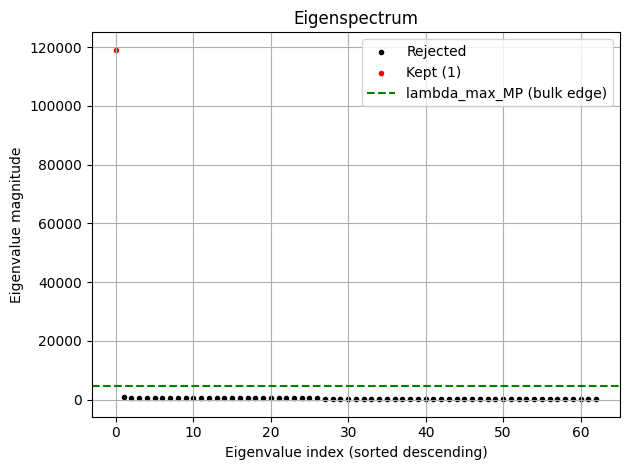

In [ ]:
%matplotlib inline

# Visual sanity check: eigenspectrum + waterfall/PSD comparison on the demo run.
klt = KLT(logger=demo_logger)
klt.load_data_from_guppi(gen["file_path"], gen["file_stem"],
                         channel=cfg.target_channel, num_samples=cfg.num_samples,
                         polarization=cfg.pol)
klt.apply_cklt(window_size=cfg.window_size, n_eigenvectors=1)

fig_eig, _ = klt.plot_eigenspectrum(n_components=1)
rmt = klt.compute_rmt_statistics()
plt.axhline(rmt["lambda_max_MP"], color="green", ls="--", label="lambda_max_MP (bulk edge)")
plt.legend()

# fig_psd, _, _ = klt.plot_psd_comparison(channel=cfg.target_channel)

import os
os.remove(gen["file_path"])  # tidy up the demo raw file

## 3. The sweep — decreasing SNR × random frequency/drift

For every SNR value (fed in **decreasing** order) we draw `n_trials` random `(frequency offset, drift rate)` pairs, generate a raw file, run the pipeline, and **append the result to a CSV immediately** so partial progress survives an interruption — important given the per-run cost.

The SNR range below straddles the phase transition for the default geometry. A calibration pass located it around **-44 to -50 dB** (per-sample injected SNR): at -38 dB the tone is solidly detected (ℓ̂ ≈ 5), at -44 dB it is marginal (ℓ̂ ≈ 0.75, just above √γ ≈ 0.46, posterior ≈ 0.23), and by -50 dB it has fallen onto the threshold and detection fails (supercritical → False, K&N → 0). Re-tune the range if you change `window_size`/`k_windows`, since the geometry moves the transition.

In [ ]:
results_path = "outputs/results/cklt_phase_transition_100t_1db.csv"

# Centred on the calibrated transition (~-44 to -50 dB). Fed in decreasing order.
snr_db_values = np.arange(-36.0, -56.0, -1)   # -36, -38, ..., -54
n_trials = 100                                     # random (freq, drift) draws per SNR

results = run_sweep(
    snr_db_values,
    config=cfg,
    n_trials=n_trials,
    freq_offset_range=(0.12, 0.42),
    drift_range_hz_s=(-5.0, 5.0),
    results_path=results_path,
    keep_raw=False,
    rng=np.random.default_rng(2026),
)
print(f"Completed {len(results)} runs -> {results_path}")

## 4. Analysis — empirical detectability vs. the BBP prediction

We aggregate the per-run results by injected SNR and compare three detectability curves:
* **`signal_confirmed`** — K&N found ≥1 signal *and* the tone was recovered at the injected frequency (a true detection).
* **`supercritical`** — the dominant eigenvalue λ₁ crossed the Marchenko–Pastur edge (the phase transition itself).
* **`posterior_h1 > 0.5`** — the TW₂ Bayesian detector fired.

The vertical reference is the injected SNR at which the *estimated* population spike `ℓ̂` crosses the theoretical threshold `√γ`.

Empirical K&N 50%-detection SNR : -47.4 dB
Theoretical BBP crossing (√γ)   : -49.2 dB   →  gap = 1.8 dB


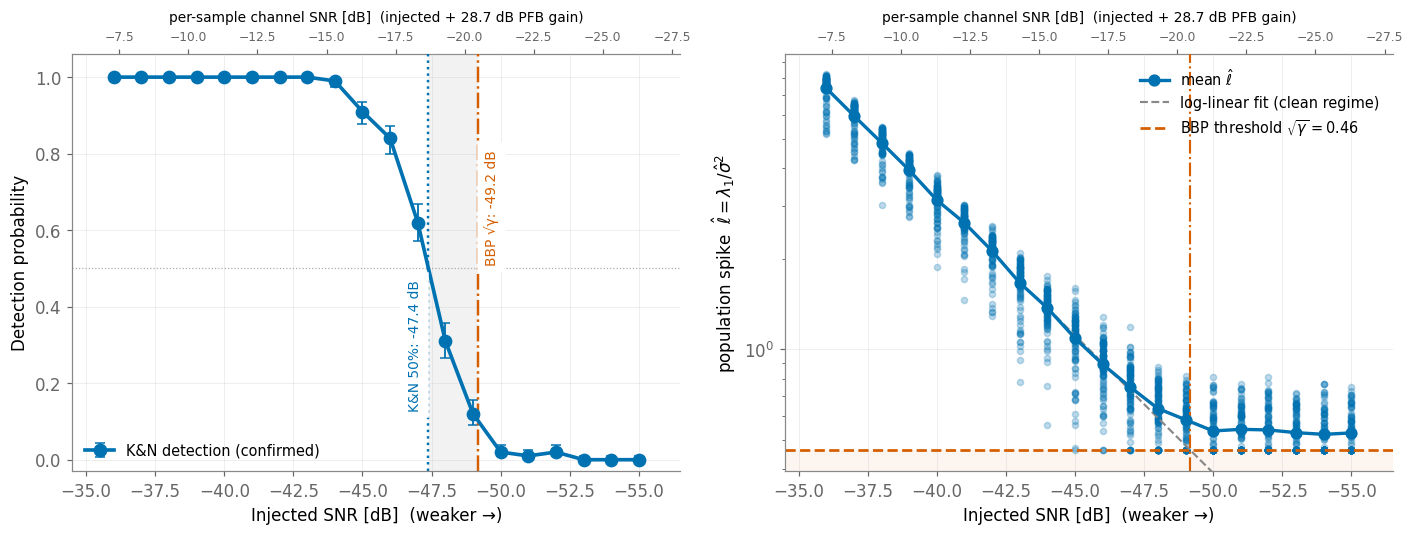

In [12]:
%matplotlib inline

# ---- load + shared style / aggregation helpers (reused by the next cell) ----
rows = load_results(results_path)
sqrt_gamma = rows[0]["bbp_threshold_sqrt_gamma"]
snrs = np.array(sorted({r["snr_db"] for r in rows}, reverse=True))

# Colorblind-safe palette (Okabe-Ito). One hue per entity, never cycled.
C_KN, C_BBP, C_REF = "#0072B2", "#E69F00", "#D55E00"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.titlesize": 12,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#888888",
    "xtick.color": "#666666", "ytick.color": "#666666",
    "axes.grid": True, "grid.color": "#CCCCCC", "grid.alpha": 0.35, "grid.linewidth": 0.6,
})
XL = (snrs.max() + 1.5, snrs.min() - 1.5)   # strong (left) → weak (right)

# Secondary top axis: injected SNR + the measured PFB channelisation gain
# (Section 5) → the per-sample SNR actually present in the recorded channel.
PFB_GAIN_DB = 28.7
def add_channel_axis(ax):
    sec = ax.secondary_xaxis("top", functions=(lambda x: x + PFB_GAIN_DB,
                                               lambda x: x - PFB_GAIN_DB))
    sec.set_xlabel(f"per-sample channel SNR [dB]  (injected + {PFB_GAIN_DB:.1f} dB PFB gain)",
                   fontsize=9, labelpad=6)
    sec.tick_params(labelsize=8, colors="#666666")
    return sec

def agg(key, pred=lambda v: bool(v)):
    return np.array([np.mean([pred(r[key]) for r in rows if r["snr_db"] == s]) for s in snrs])
def per_snr(key, finite=False):
    out = []
    for s in snrs:
        vals = [r[key] for r in rows if r["snr_db"] == s]
        out.append([v for v in vals if v == v] if finite else vals)
    return out
def wilson(k, n, z=1.0):  # 68% score interval for the detection fraction
    if n == 0: return 0.0, 0.0
    p, d = k / n, 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return max(0.0, c - h), min(1.0, c + h)

conf, sup = agg("signal_confirmed"), agg("supercritical")
ncount = np.array([sum(r["snr_db"] == s for r in rows) for s in snrs])
kcount = np.array([sum(r["signal_confirmed"] for r in rows if r["snr_db"] == s) for s in snrs])
lo = np.array([wilson(k, n)[0] for k, n in zip(kcount, ncount)])
hi = np.array([wilson(k, n)[1] for k, n in zip(kcount, ncount)])
lhat_lists = per_snr("l_pop_hat")
lhat_mean = np.array([np.mean(x) for x in lhat_lists])

# Empirical K&N 50%-detection SNR, and theoretical BBP crossing (extrapolate the
# clean-regime log-linear ℓ̂(SNR) down to √γ, since ℓ̂ itself floors at √γ).
sa = snrs[np.argsort(snrs)]; ca = conf[np.argsort(snrs)]
emp50 = np.interp(0.5, ca, sa) if ca.min() < 0.5 < ca.max() else np.nan
clean = lhat_mean > 1.2
if clean.sum() >= 2:
    pfit = np.polyfit(snrs[clean], np.log10(lhat_mean[clean]), 1)
    theo = (np.log10(sqrt_gamma) - pfit[1]) / pfit[0]
else:
    pfit, theo = None, np.nan

# ================= Figure 1 — the phase transition =================
fig, (axA, axB) = plt.subplots(1, 2, figsize=(13, 5))

if np.isfinite(theo) and np.isfinite(emp50):
    axA.axvspan(*sorted([emp50, theo]), color="#BBBBBB", alpha=0.18, lw=0)
axA.axhline(0.5, color="#AAAAAA", lw=0.8, ls=":")
# axA.plot(snrs, sup, "s--", color=C_BBP, mfc="white", mec=C_BBP, ms=7, lw=1.8,
#          label="supercritical (naive λ₁ > MP edge)")
axA.errorbar(snrs, conf, yerr=[np.abs(conf - lo), np.abs(hi - conf)],
              fmt="o-", color=C_KN, ms=8, lw=2.4,
             capsize=3, ecolor=C_KN, elinewidth=1.2, label="K&N detection (confirmed)")
if np.isfinite(emp50):
    axA.axvline(emp50, color=C_KN, ls=":", lw=1.6)
    axA.text(emp50 + 0.25, 0.30, f"K&N 50%: {emp50:.1f} dB", color=C_KN, fontsize=9,
             rotation=90, ha="right", va="center", backgroundcolor="white")
if np.isfinite(theo):
    axA.axvline(theo, color=C_REF, ls="-.", lw=1.6)
    axA.text(theo - 0.25, 0.66, f"BBP √γ: {theo:.1f} dB", color=C_REF, fontsize=9,
             rotation=90, ha="left", va="center", backgroundcolor="white")
axA.set_xlim(*XL); axA.set_ylim(-0.03, 1.06)
axA.set_xlabel("Injected SNR [dB]  (weaker →)"); axA.set_ylabel("Detection probability")
# axA.set_title("A · Phase transition: K&N vs. naive edge test", pad=34)
axA.legend(loc="lower left", frameon=False, fontsize=9.5)
add_channel_axis(axA)

for s, xs in zip(snrs, lhat_lists):
    axB.scatter([s] * len(xs), xs, s=16, color=C_KN, alpha=0.25, zorder=2)
axB.plot(snrs, lhat_mean, "o-", color=C_KN, ms=7, lw=2.2, zorder=4, label=r"mean $\hat{\ell}$")
if pfit is not None:
    xf = np.linspace(snrs[clean].min(), theo - 1, 50)
    axB.plot(xf, 10 ** np.polyval(pfit, xf), color="#888888", ls="--", lw=1.4, zorder=3,
             label="log-linear fit (clean regime)")
    axB.axvline(theo, color=C_REF, ls="-.", lw=1.4)
axB.axhline(sqrt_gamma, color=C_REF, ls="--", lw=1.8,
            label=r"BBP threshold $\sqrt{\gamma}=$" + f"{sqrt_gamma:.2f}")
ymin = min(v for x in lhat_lists for v in x) * 0.85
axB.axhspan(ymin, sqrt_gamma, color=C_REF, alpha=0.06, lw=0)
axB.set_yscale("log"); axB.set_xlim(*XL); axB.set_ylim(bottom=ymin)
axB.set_xlabel("Injected SNR [dB]  (weaker →)")
axB.set_ylabel(r"population spike  $\hat{\ell}=\lambda_1/\hat{\sigma}^2$")
# axB.set_title(r"B · Estimated spike vs. threshold  ($\hat{\ell}$ floors at $\sqrt{\gamma}$)", pad=34)
axB.legend(loc="upper right", frameon=False, fontsize=9.5)
add_channel_axis(axB)
fig.tight_layout()

print(f"Empirical K&N 50%-detection SNR : {emp50:.1f} dB")
print(f"Theoretical BBP crossing (√γ)   : {theo:.1f} dB   →  gap = {abs(emp50 - theo):.1f} dB")

**Figure 2 — reconstruction quality and K&N rank.**
* **Panel C** — spectral SNR of the C-KLT reconstruction vs. injection, over the noisy-input floor; the shaded band is the denoising **gain**. Points (detections only) are coloured by `ℓ̂`. As the injection weakens the gain shrinks and, once K&N stops detecting, there is no reconstruction to plot.
* **Panel D** — the mean number of eigenvalues K&N keeps for the reconstruction (`n_eig_recon`). In the detection regime it sits at the **true rank = 1**; it drops to 0 across the transition. Bars slightly above 1 are the rare runs where K&N flagged a spurious second eigenvalue.

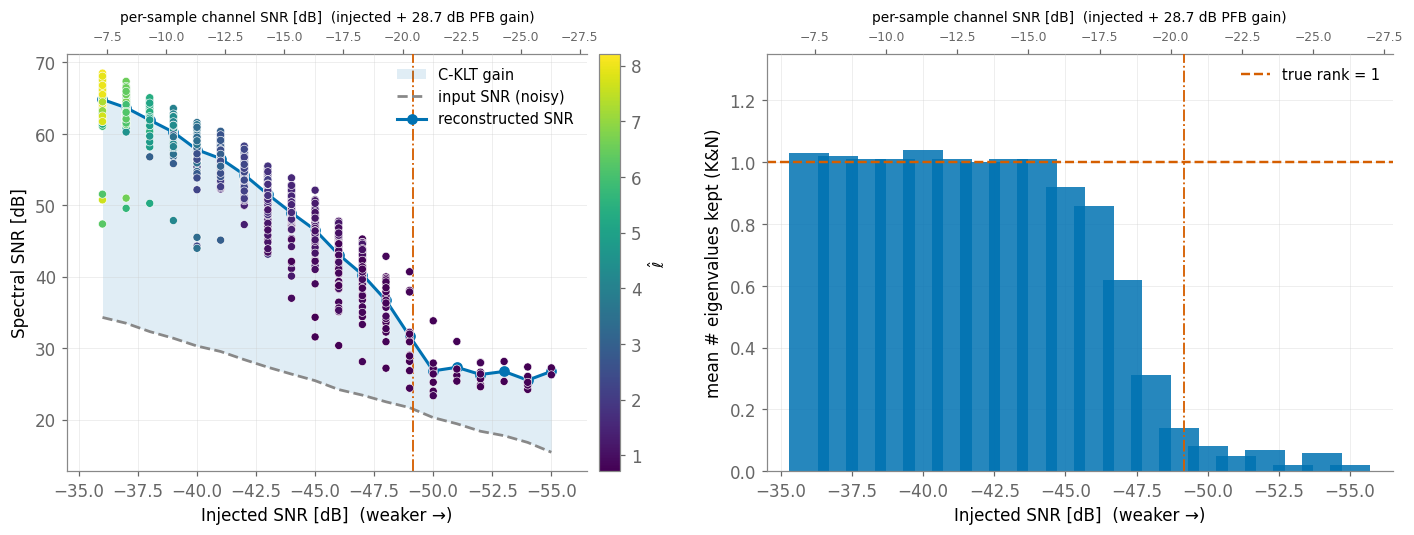

K&N-vs-BBP agreement over all runs: 79%
runs where K&N kept >1 eigenvalue : 18 / 2000


In [13]:
# ================= Figure 2 — reconstruction quality & K&N rank =================
fig2, (axC, axD) = plt.subplots(1, 2, figsize=(13, 5))

inp_mean = np.array([np.mean([r["input_snr_db"] for r in rows if r["snr_db"] == s]) for s in snrs])
rec_lists = per_snr("recon_snr_db", finite=True)
rec_mean = np.array([np.mean(x) if x else np.nan for x in rec_lists])
valid = ~np.isnan(rec_mean)

# Panel C — reconstruction gain: input floor vs. C-KLT reconstruction.
axC.fill_between(snrs[valid], inp_mean[valid], rec_mean[valid], color=C_KN, alpha=0.12, lw=0,
                 label="C-KLT gain")
det = [r for r in rows if r["signal_found"] and r["recon_snr_db"] == r["recon_snr_db"]]
sc = axC.scatter([r["snr_db"] for r in det], [r["recon_snr_db"] for r in det],
                 c=[r["l_pop_hat"] for r in det], cmap="viridis", s=28, zorder=3,
                 edgecolor="white", linewidth=0.4)
axC.plot(snrs, inp_mean, "--", color="#888888", lw=1.8, label="input SNR (noisy)")
axC.plot(snrs[valid], rec_mean[valid], "o-", color=C_KN, ms=6, lw=2.0, label="reconstructed SNR")
if np.isfinite(theo):
    axC.axvline(theo, color=C_REF, ls="-.", lw=1.2)
axC.set_xlim(*XL)
axC.set_xlabel("Injected SNR [dB]  (weaker →)"); axC.set_ylabel("Spectral SNR [dB]")
# axC.set_title("C · Reconstruction gain (detections only)", pad=34)
axC.legend(loc="upper right", frameon=False, fontsize=9.5)
add_channel_axis(axC)
cb = fig2.colorbar(sc, ax=axC, pad=0.02); cb.set_label(r"$\hat{\ell}$", fontsize=10)

# Panel D — how many eigenvalues K&N keeps for the reconstruction.
neig_mean = agg("n_eig_recon", pred=lambda v: v)
axD.bar(snrs, neig_mean, width=1.4, color=C_KN, alpha=0.85, zorder=2)
axD.axhline(1.0, color=C_REF, ls="--", lw=1.6, label="true rank = 1")
if np.isfinite(theo):
    axD.axvline(theo, color=C_REF, ls="-.", lw=1.2)
axD.set_xlim(*XL); axD.set_ylim(0, max(1.35, neig_mean.max() * 1.15))
axD.set_xlabel("Injected SNR [dB]  (weaker →)"); axD.set_ylabel("mean # eigenvalues kept (K&N)")
# axD.set_title("D · Eigenvalues K&N selects for reconstruction", pad=34)
axD.legend(loc="upper right", frameon=False, fontsize=9.5)
add_channel_axis(axD)
fig2.tight_layout(); plt.show()

agree = np.mean([r["kn_agrees_bbp"] for r in rows])
print(f"K&N-vs-BBP agreement over all runs: {agree*100:.0f}%")
print(f"runs where K&N kept >1 eigenvalue : {sum(r['n_signals_KN'] > 1 for r in rows)} / {len(rows)}")

## 5. Injected vs. effective SNR — what the PFB does to the signal

The `snr_db` fed to `generate_cklt_raw` is a **per-sample, pre-PFB** ratio (`level = noise_std·√(2·10^(SNR/10))`). It is a convenient control knob, **not** the SNR of the recorded data: before anything is written to disk the voltages pass through a polyphase filterbank and 8-bit quantisers, which change the effective SNR.

This cell measures that transformation empirically. For a few injected SNRs it records one file and compares three quantities in the **target coarse channel**:
1. **Injected** per-sample SNR (the knob) — the `y = x` reference.
2. **Per-sample SNR in the recorded channel** — signal power vs. noise power, with the noise power read from a signal-free channel (`target_channel + 12`) of the *same* file (white noise ⇒ every channel carries the same noise floor).
3. **Spectral SNR** over the whole record (the coherent-integration view, `helpers.spectral_snr`).

Expectation: a narrowband tone is concentrated by the PFB into one channel while noise spreads across all `num_branches` channels, so the PFB adds a **near-constant processing gain** of order `10·log10(num_branches)` before recording — i.e. the injected SNR is *not* the data SNR. (This cell generates a handful of extra recordings, ~1 min on CPU.)

Reading blocks: 32.8ksamp [00:00, 379ksamp/s]                 
Reading blocks: 32.8ksamp [00:00, 281ksamp/s]                 
Reading blocks: 32.8ksamp [00:00, 366ksamp/s]                 
Reading blocks: 32.8ksamp [00:00, 440ksamp/s]                 
Reading blocks: 32.8ksamp [00:00, 350ksamp/s]                 
Reading blocks: 32.8ksamp [00:00, 413ksamp/s]                 
Reading blocks: 32.8ksamp [00:00, 296ksamp/s]                 
Reading blocks: 32.8ksamp [00:00, 463ksamp/s]                 
Reading blocks: 32.8ksamp [00:00, 431ksamp/s]                 
Reading blocks: 32.8ksamp [00:00, 460ksamp/s]                 
Reading blocks: 32.8ksamp [00:00, 513ksamp/s]                 
Reading blocks: 32.8ksamp [00:00, 527ksamp/s]                 


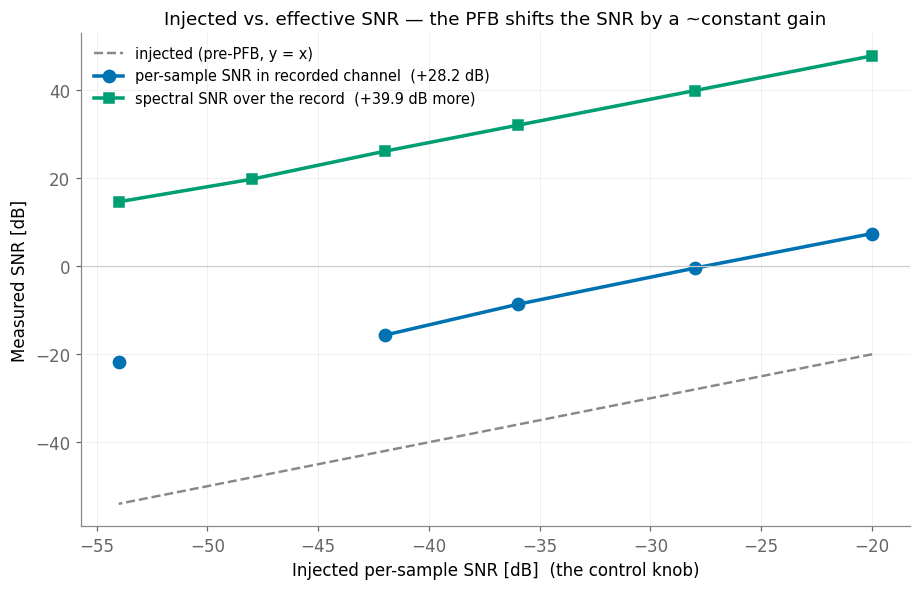

PFB channelisation gain  (injected → channel): +28.2 dB   [theory 10·log10(num_branches) = 30.1 dB]
Coherent FFT gain        (channel → spectral) : +39.9 dB   [theory 10·log10(N) = 42.7 dB]
→ an injected -20 dB tone actually sits at +7.4 dB per sample in its channel: the injected SNR is not the data SNR.


In [9]:
# How the SNR is transformed: injected (pre-PFB) → recorded channel → spectral.
from helpers import spectral_snr
import os

snr_probe_log = SimpleLogger(level=LogLevel.WARNING, console_output=False, file_output=False)
off_channel = cfg.target_channel + 12          # a signal-free coarse channel (noise only)
inj_list = np.array([-20.0, -28.0, -36.0, -42.0, -48.0, -54.0])

chan_db, spec_db = [], []
for snr in inj_list:
    gen = generate_cklt_raw(snr, 0.317, 2.0, config=cfg,
                            file_stem="outputs/raw_data/snr_probe", seed=7)
    kt = KLT(logger=snr_probe_log)   # target channel: signal + noise
    kt.load_data_from_guppi(gen["file_path"], gen["file_stem"], channel=cfg.target_channel,
                            num_samples=cfg.num_samples, polarization=cfg.pol)
    x_sig = np.asarray(kt.signal)
    kn = KLT(logger=snr_probe_log)   # off channel: noise only
    kn.load_data_from_guppi(gen["file_path"], gen["file_stem"], channel=off_channel,
                            num_samples=cfg.num_samples, polarization=cfg.pol)
    x_noise = np.asarray(kn.signal)
    os.remove(gen["file_path"])

    P_tot, P_n = np.mean(np.abs(x_sig) ** 2), np.mean(np.abs(x_noise) ** 2)
    P_s = max(P_tot - P_n, 0.0)
    chan_db.append(10 * np.log10(P_s / P_n) if P_s > 0 else np.nan)
    spec_db.append(10 * np.log10(spectral_snr(x_sig)[0]))

chan_db, spec_db = np.array(chan_db), np.array(spec_db)
pfb_gain = np.nanmean(chan_db - inj_list)      # injected → recorded channel
fft_gain = np.nanmean(spec_db - chan_db)       # channel → spectral (coherent)

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.plot(inj_list, inj_list, "--", color="#888888", lw=1.6, label="injected (pre-PFB, y = x)")
ax.plot(inj_list, chan_db, "o-", color="#0072B2", lw=2.3, ms=8,
        label=f"per-sample SNR in recorded channel  (+{pfb_gain:.1f} dB)")
ax.plot(inj_list, spec_db, "s-", color="#009E73", lw=2.3, ms=7,
        label=f"spectral SNR over the record  (+{fft_gain:.1f} dB more)")
ax.axhline(0, color="#CCCCCC", lw=0.8)
ax.set_xlabel("Injected per-sample SNR [dB]  (the control knob)")
ax.set_ylabel("Measured SNR [dB]")
ax.set_title("Injected vs. effective SNR — the PFB shifts the SNR by a ~constant gain")
ax.grid(alpha=0.3); ax.legend(frameon=False, fontsize=9.5, loc="upper left")
fig.tight_layout(); plt.show()

print(f"PFB channelisation gain  (injected → channel): +{pfb_gain:4.1f} dB   "
      f"[theory 10·log10(num_branches) = {10*np.log10(cfg.num_branches):.1f} dB]")
print(f"Coherent FFT gain        (channel → spectral) : +{fft_gain:4.1f} dB   "
      f"[theory 10·log10(N) = {10*np.log10(cfg.num_samples):.1f} dB]")
print(f"→ an injected {inj_list[0]:.0f} dB tone actually sits at {chan_db[0]:+.1f} dB per sample "
      f"in its channel: the injected SNR is not the data SNR.")

### Notes & extensions
* The results CSV (`outputs/results/cklt_phase_transition.csv`) is appended row-by-row, so a long sweep can be interrupted and resumed (rows already written are preserved; re-running appends new ones).
* All recorded columns are documented in `helpers.RESULT_FIELDS`. Beyond the requested outputs (initial SNR, reconstructed SNR, `n_signals_KN`, `signal_found`, `supercritical`) it also stores: the estimated population spike `ℓ̂`, its margin over `√γ`, the eigenvalue gap ratio, the TW₂ false-alarm probability and posterior, the recovered-frequency error, and a K&N-vs-BBP agreement flag.
* To push the sweep deeper, increase `n_trials` for tighter detection-rate estimates, or widen `snr_db_values` to bracket the transition more fully.
* `cfg.window_size` / `cfg.k_windows` change the geometry: raising `W` (at fixed `K`) increases `γ` and pushes `√γ` up, making detection harder — a second axis for the phase-transition study.